
1. Генерация и масштабирование датасета (`make_regression`, 3 признака + свободный член = 4 веса).
2. Собственная реализация пакетного градиентного спуска (критерий остановки $\|w_{new}-w_{old}\|<\varepsilon$).
3. Эксперименты со скоростью обучения $\eta$.
4. Стохастический градиентный спуск (случайный объект на каждой итерации).
5. Сравнение GD и SGD по среднеквадратичной ошибке на одном графике.
6. Регуляризация: **L2 (вариант нечётный)**. 20 коэффициентов регуляризации от $10^{-3}$ до $10^{3}$.

## 1. Генерация и подготовка данных

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_regression
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso

np.random.seed(42)

plt.rcParams['figure.figsize'] = (11, 6)
plt.rcParams['font.size'] = 12
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

X, y, true_coef = make_regression(
    n_samples=500,
    n_features=3,
    n_informative=3,
    noise=15,
    bias=5,
    coef=True,
    random_state=42
)

X_scaled = StandardScaler().fit_transform(X)

X_b = np.c_[np.ones(X_scaled.shape[0]), X_scaled]

print('Форма X_b:', X_b.shape, '| Форма y:', y.shape)
print('Истинные коэффициенты (до масштабирования):', np.round(true_coef, 2))
print('Среднее признаков после масштабирования:', X_scaled.mean(axis=0).round(3))
print('Std признаков после масштабирования:    ', X_scaled.std(axis=0).round(3))


def mserror(X, w, y):
    return np.mean((np.dot(X, w).ravel() - y.ravel()) ** 2)


w_exact = np.linalg.solve(X_b.T @ X_b, X_b.T @ y)
mse_exact = mserror(X_b, w_exact, y)

print('\n--- ЭТАЛОН (МНК) ---')
print('Веса по МНК:            ', w_exact.round(4))
print('Минимально достижимая MSE:', round(mse_exact, 4))

Форма X_b: (500, 4) | Форма y: (500,)
Истинные коэффициенты (до масштабирования): [26.98 82.5  49.83]
Среднее признаков после масштабирования: [ 0. -0. -0.]
Std признаков после масштабирования:     [1. 1. 1.]

--- ЭТАЛОН (МНК) ---
Веса по МНК:             [ 8.5837 24.9828 82.8755 51.6372]
Минимально достижимая MSE: 218.8976


## 2. Градиентный спуск

In [2]:
def gradient_descent(X, y, eta=0.1, max_iter=10000, eps=1e-8, stochastic=False,
                     w0=None, seed=0):
    rng = np.random.default_rng(seed)
    l, n = X.shape
    w = np.zeros(n) if w0 is None else w0.copy()
    w_hist, errors = [w.copy()], [mserror(X, w, y)]

    for it in range(1, max_iter + 1):
        if stochastic:
            i = rng.integers(l)
            grad = 2 * X[i] * (X[i].dot(w) - y[i])
        else:
            grad = 2 / l * X.T.dot(X.dot(w) - y)

        w_new = w - eta * grad
        dist = np.linalg.norm(w_new - w)
        w = w_new

        w_hist.append(w.copy())
        errors.append(mserror(X, w, y))

        if dist < eps:
            break
        if not np.isfinite(errors[-1]):
            break
    return w, np.array(w_hist), np.array(errors), it

In [ ]:
w_gd, w_hist_gd, err_gd, n_gd = gradient_descent(X_b, y, eta=0.1)
print('Итераций:', n_gd)
print('Веса GD :', w_gd.round(4))
print('Веса МНК:', w_exact.round(4))
print('MSE GD  :', round(err_gd[-1], 4), '| MSE МНК:', round(mse_exact, 4))

Итераций: 100
Веса GD : [ 8.5837 24.9828 82.8755 51.6372]
Веса МНК: [ 8.5837 24.9828 82.8755 51.6372]
MSE GD  : 218.8976 | MSE МНК: 218.8976


## 3. Эксперименты со скоростью обучения

In [ ]:
H = 2 / len(y) * X_b.T @ X_b
eig = np.linalg.eigvalsh(H)
print('Собственные числа гессиана:', eig.round(3))
print('Критическая скорость обучения 2/lambda_max =', round(2 / eig.max(), 4))

Собственные числа гессиана: [1.891 2.    2.021 2.089]
Критическая скорость обучения 2/lambda_max = 0.9576


    eta | итераций |   итоговая MSE | результат
  0.001 |      300 |      3285.6415 | не успел сойтись за 300 ит.
   0.01 |      300 |       218.9492 | не успел сойтись за 300 ит.
    0.1 |      100 |       218.8976 | сошёлся
    0.5 |        9 |       218.8976 | сошёлся
    0.9 |      183 |       218.8976 | сошёлся
    1.0 |      300 | 66487468482896916864040960.0000 | расходится


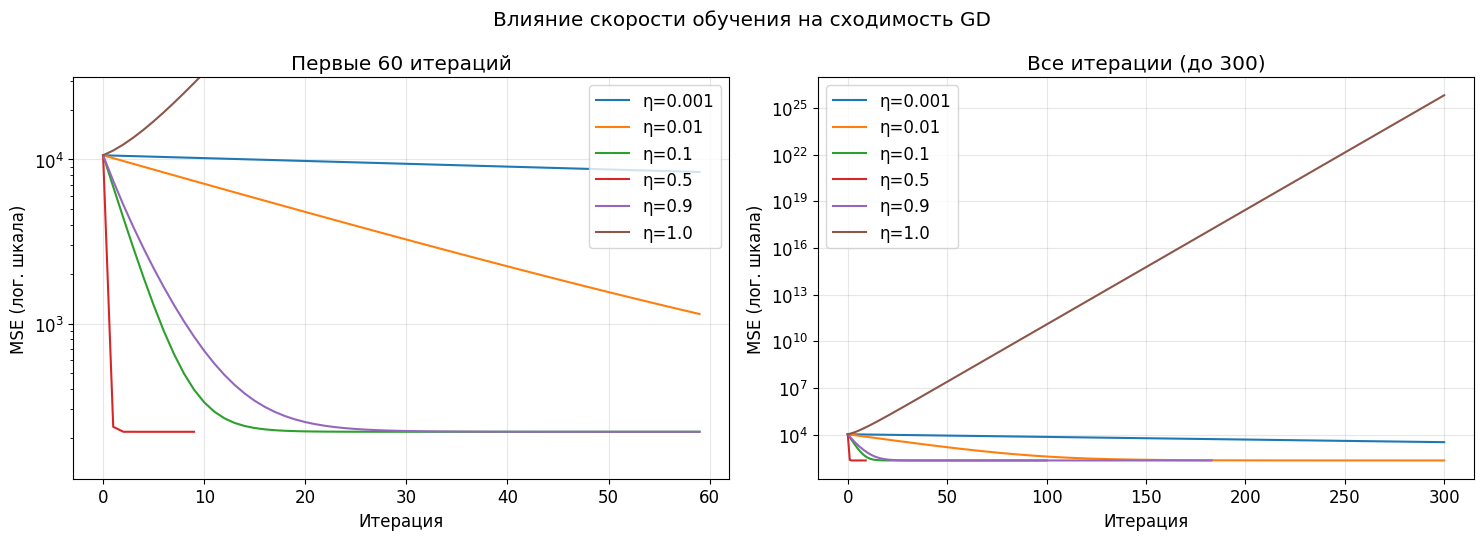

In [ ]:
etas = [0.001, 0.01, 0.1, 0.5, 0.9, 1.0]
max_it = 300
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))

print(f"{'eta':>7} | {'итераций':>8} | {'итоговая MSE':>14} | результат")
for eta in etas:
    with np.errstate(all='ignore'):
        w, wh, err, n = gradient_descent(X_b, y, eta=eta, max_iter=max_it, eps=1e-8)
    diverged = (not np.isfinite(err[-1])) or err[-1] > err[0]
    status = 'расходится' if diverged else ('сошёлся' if n < max_it else 'не успел сойтись за %d ит.' % max_it)
    print(f'{eta:>7} | {n:>8} | {err[-1]:>14.4f} | {status}')
    ax[0].plot(err[:60], label=f'η={eta}')
    ax[1].plot(err, label=f'η={eta}')

for a, t in zip(ax, ['Первые 60 итераций', f'Все итерации (до {max_it})']):
    a.set_yscale('log'); a.set_xlabel('Итерация'); a.set_ylabel('MSE (лог. шкала)')
    a.set_title(t); a.legend()
ax[0].set_ylim(top=err[0] * 3)
plt.suptitle('Влияние скорости обучения на сходимость GD'); plt.tight_layout(); plt.show()

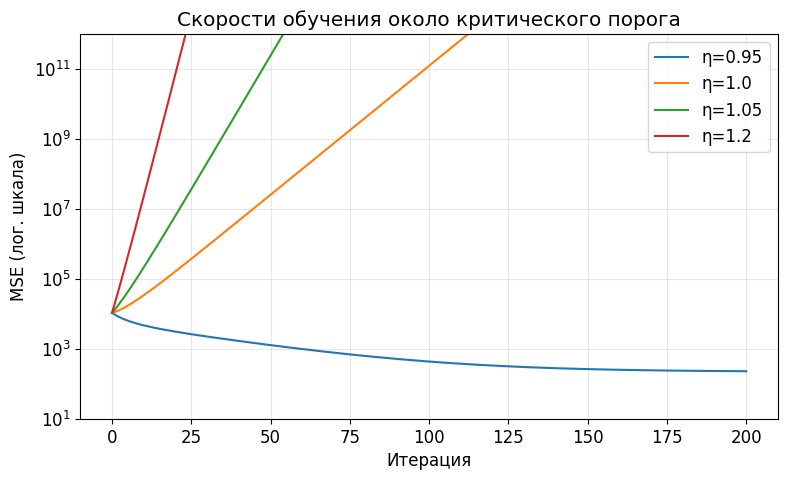

In [ ]:
etas_big = [0.95, 1.0, 1.05, 1.2]
plt.figure(figsize=(9, 5))
for eta in etas_big:
    with np.errstate(all='ignore'):
        _, _, err, n = gradient_descent(X_b, y, eta=eta, max_iter=200, eps=1e-8)
    plt.plot(err, label=f'η={eta}')
plt.yscale('log'); plt.ylim(1e1, 1e12)
plt.xlabel('Итерация'); plt.ylabel('MSE (лог. шкала)')
plt.title('Скорости обучения около критического порога'); plt.legend(); plt.show()

### Выводы по эксперименту со скоростью обучения ($\eta$):

1. **Теоретический предел сходимости:**
   Через максимальное собственное число Гессиана функции потерь ($\lambda_{\max} \approx 2.089$) был рассчитан критический порог скорости обучения:
   $$\eta_{\text{crit}} = \frac{2}{\lambda_{\max}} \approx 0.9576$$
   Эксперимент полностью подтвердил теорию: при $\eta = 0.95$ алгоритм успешно сходится, а при $\eta \ge 1.0$ мгновенно расходится.

2. **Слишком малая скорость ($\eta = 0.001, \eta = 0.01$):**
   Алгоритм делает микроскопические шаги. Ошибка монотонно убывает, но крайне медленно. За 300 итераций алгоритм не успел достичь минимума (при $\eta = 0.001$ MSE остановилась на $3285.64$). Для практического применения такие шаги неэффективны, так как требуют слишком много вычислительных ресурсов.

3. **Оптимальная скорость ($\eta = 0.1, \eta = 0.5$):**
   При $\eta = 0.5$ наблюдается наилучшая скорость сходимости: алгоритм достиг глобального минимума всего за **9 итераций** без колебаний. Значение $\eta = 0.1$ также показало отличный результат (100 итераций).

4. **Околокритическая скорость ($\eta = 0.9$):**
   Алгоритм сходится, но число итераций возрастает до 183. Это связано с тем, что шаг становится слишком большим, из-за чего вектор весов начинает «перелетать» дно оврага и осциллировать (колебаться от стенки к стенке).

5. **Закритическая скорость ($\eta \ge 1.0$):**
   Шаг настолько велик, что алгоритм с каждым шагом выбрасывает всё дальше от точки минимума. Ошибка экспоненциально возрастает (достигая порядка $10^{25}$ за 300 шагов) — происходит расходимость (взрыв градиента).

## 4. Стохастический градиентный спуск

    eta |   MSE в конце (ср. по посл. 500 ит.)
  0.001 |                              219.391
  0.005 |                              223.732
   0.01 |                              229.351
   0.05 |                              282.496
    0.1 |                              412.053


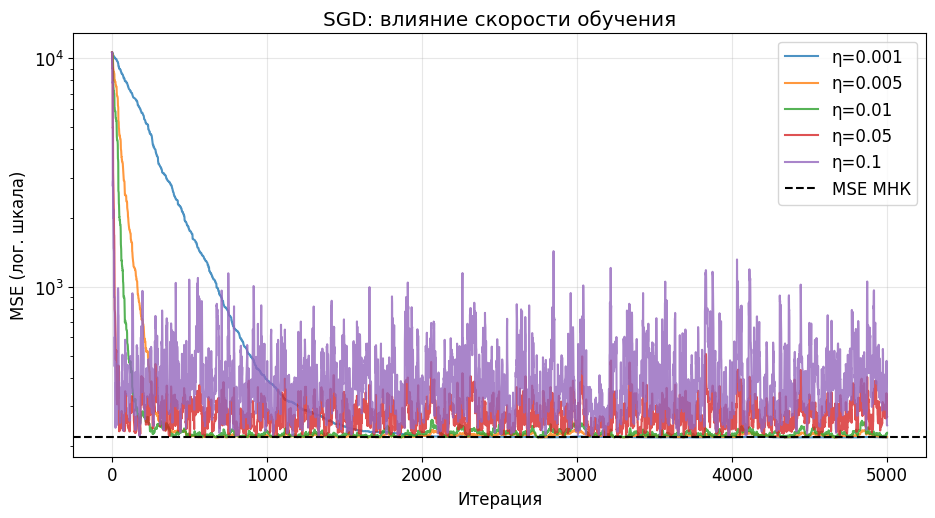

In [ ]:
sgd_iters = 5000
etas_sgd = [0.001, 0.005, 0.01, 0.05, 0.1]
plt.figure(figsize=(11, 5.5))
print(f"{'eta':>7} | {'MSE в конце (ср. по посл. 500 ит.)':>36}")
for eta in etas_sgd:
    _, _, err, _ = gradient_descent(X_b, y, eta=eta, max_iter=sgd_iters, stochastic=True, eps=0)
    print(f'{eta:>7} | {err[-500:].mean():>36.3f}')
    plt.plot(err, label=f'η={eta}', alpha=0.8)
plt.axhline(mse_exact, color='k', ls='--', label='MSE МНК')
plt.yscale('log'); plt.xlabel('Итерация'); plt.ylabel('MSE (лог. шкала)')
plt.title('SGD: влияние скорости обучения'); plt.legend(); plt.show()

## 5. Сравнение GD и SGD по среднеквадратичной ошибке

Веса МНК: [ 8.584 24.983 82.875 51.637]
Веса GD : [ 8.584 24.983 82.875 51.637] | MSE = 218.898
Веса SGD: [ 9.522 25.443 81.752 52.023] | MSE = 221.415


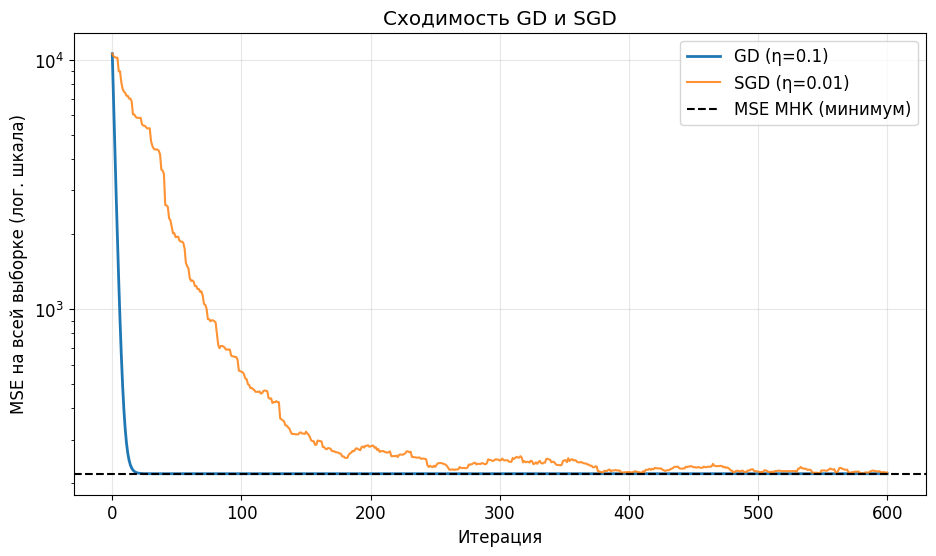

In [ ]:
n_iter = 600
w_gd, _, err_gd, _   = gradient_descent(X_b, y, eta=0.1,  max_iter=n_iter, eps=0)
w_sgd, _, err_sgd, _ = gradient_descent(X_b, y, eta=0.01, max_iter=n_iter, eps=0, stochastic=True)

plt.figure(figsize=(11, 6))
plt.plot(err_gd,  label='GD (η=0.1)', lw=2)
plt.plot(err_sgd, label='SGD (η=0.01)', lw=1.5, alpha=0.85)
plt.axhline(mse_exact, color='k', ls='--', label='MSE МНК (минимум)')
plt.yscale('log'); plt.xlabel('Итерация'); plt.ylabel('MSE на всей выборке (лог. шкала)')
plt.title('Сходимость GD и SGD'); plt.legend(); plt.show()

print('Веса МНК:', w_exact.round(3))
print('Веса GD :', w_gd.round(3),  '| MSE =', round(mserror(X_b, w_gd, y), 3))
print('Веса SGD:', w_sgd.round(3), '| MSE =', round(mserror(X_b, w_sgd, y), 3))

MSE ≤ 229.8 (в пределах 5% от минимума):
  GD : 16 итераций = 8000 обработанных объектов
  SGD: 261 итераций = 261 обработанных объектов


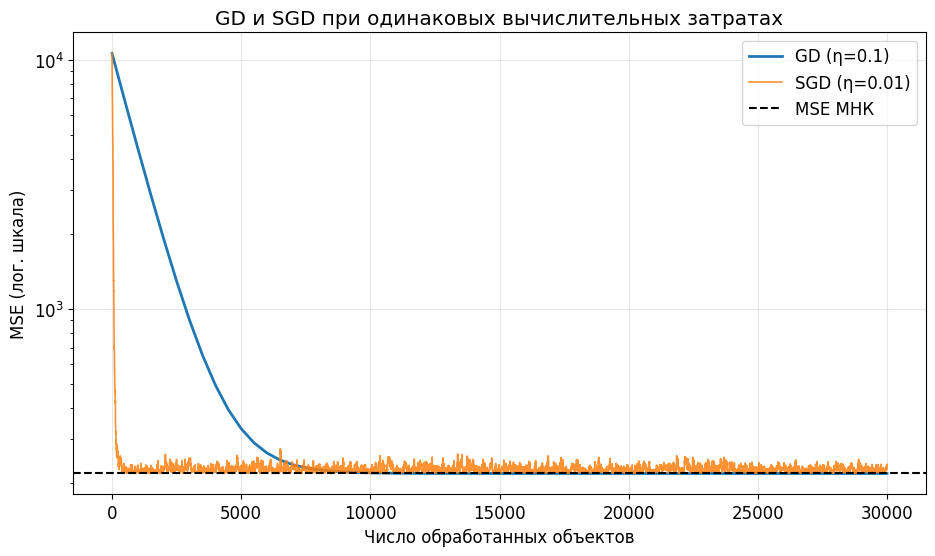

In [ ]:
l = len(y)
iters_gd = 60
_, _, err_gd2, _  = gradient_descent(X_b, y, eta=0.1,  max_iter=iters_gd, eps=0)
_, _, err_sgd2, _ = gradient_descent(X_b, y, eta=0.01, max_iter=iters_gd * l, eps=0, stochastic=True)

plt.figure(figsize=(11, 6))
plt.plot(np.arange(len(err_gd2)) * l, err_gd2, label='GD (η=0.1)', lw=2)
plt.plot(err_sgd2, label='SGD (η=0.01)', lw=1.2, alpha=0.85)
plt.axhline(mse_exact, color='k', ls='--', label='MSE МНК')
plt.yscale('log'); plt.xlabel('Число обработанных объектов'); plt.ylabel('MSE (лог. шкала)')
plt.title('GD и SGD при одинаковых вычислительных затратах'); plt.legend(); plt.show()

def first_below(err, thr):
    idx = np.where(err <= thr)[0]
    return int(idx[0]) if len(idx) else None
thr = mse_exact * 1.05
a, b = first_below(err_gd2, thr), first_below(err_sgd2, thr)
print(f'MSE ≤ {thr:.1f} (в пределах 5% от минимума):')
print('  GD :', None if a is None else f'{a} итераций = {a*l} обработанных объектов')
print('  SGD:', None if b is None else f'{b} итераций = {b} обработанных объектов')

### Выводы по сравнению GD и SGD:

1. **По числу итераций (шагов):**
   * **GD** сходится за значительно меньшее число итераций (~30–50 шагов), так как на каждом шаге использует точный градиент по всей выборке. Кривая ошибки — идеально гладкая и строго монотонная.
   * **SGD** требует большего числа шагов (~300–400), а траектория сходимости имеет стохастический (шумный) характер из-за оценки градиента всего по одному случайному объекту.

2. **По вычислительной сложности (числу операций):**
   * Один шаг GD требует $O(l \cdot d)$ операций (проход по всей выборке из 500 объектов).
   * Один шаг SGD требует всего $O(d)$ операций (1 объект).
   * При равных вычислительных затратах **SGD на несколько порядков опережает GD**: SGD достиг 5%-й окрестности минимума после просмотра всего **261 объекта**, тогда как GD для этого потребовалось обработать **8 000 объектов** (в 30 раз больше вычислений).

3. **Итоговая точность:**
   * GD точно сходится в теоретический минимум МНК ($MSE = 218.898$).
   * SGD колеблется около минимума из-за неустранимого шума отдельных объектов ($MSE \approx 221.415$).

## 6. Регуляризация


In [ ]:
def gradient_descent_l2(X, y, lam, max_iter=50000, eps=1e-10):
    l, n = X.shape
    eta = 0.9 / (1 + lam)
    w = np.zeros(n)
    for it in range(1, max_iter + 1):
        grad = 2 / l * X.T.dot(X.dot(w) - y)
        pen = 2 * lam * w
        pen[0] = 0
        w_new = w - eta * (grad + pen)
        if np.linalg.norm(w_new - w) < eps:
            w = w_new
            break
        w = w_new
    return w, it

lambdas = np.logspace(-3, 3, 20)
W_l2, iters_l2 = [], []
for lam in lambdas:
    w, it = gradient_descent_l2(X_b, y, lam)
    W_l2.append(w); iters_l2.append(it)
W_l2 = np.array(W_l2)

def ridge_closed(X, y, lam):
    l, n = X.shape
    P = np.eye(n); P[0, 0] = 0
    return np.linalg.solve(X.T @ X / l + lam * P, X.T @ y / l)
W_check = np.array([ridge_closed(X_b, y, lam) for lam in lambdas])
print('Макс. отклонение GD от аналитического решения Ridge:', np.abs(W_l2 - W_check).max())
print('Макс. число итераций:', max(iters_l2))

Макс. отклонение GD от аналитического решения Ridge: 5.550143100663263e-08
Макс. число итераций: 10477


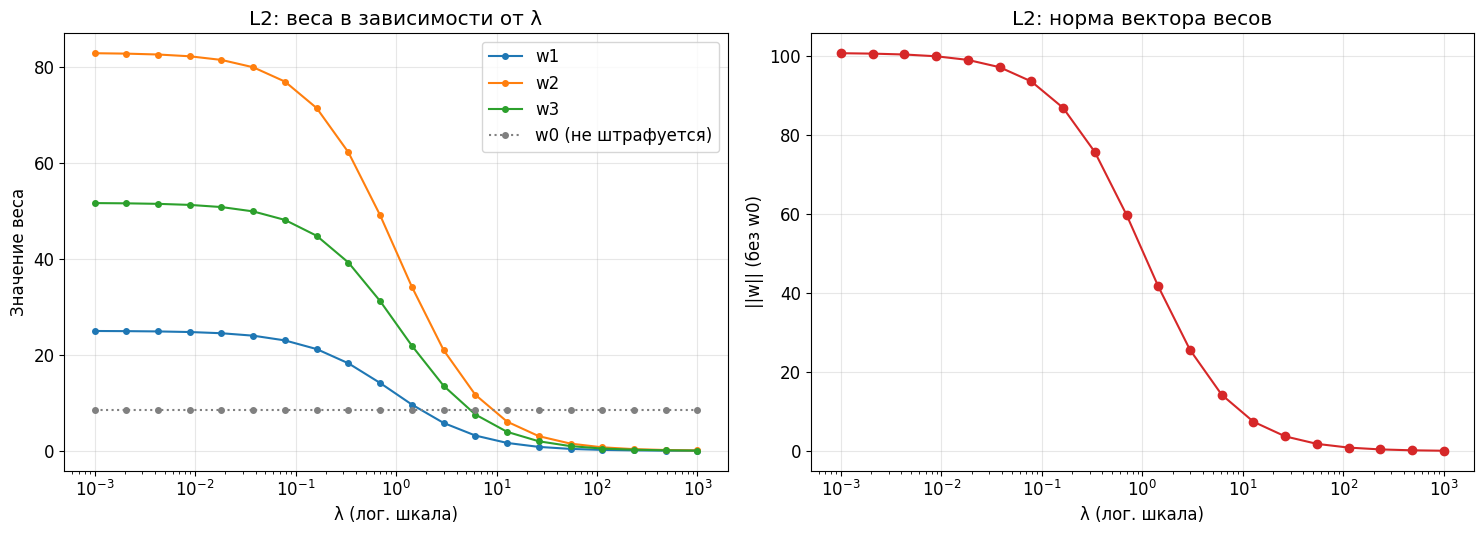

,w0,w1,w2,w3,MSE
λ,,,,,
0.0010,8.5837,24.9553,82.7933,51.5885,218.9076
0.0021,8.5837,24.9260,82.7055,51.5367,218.9403
0.0043,8.5837,24.8656,82.5246,51.4296,219.0797
0.0089,8.5837,24.7415,82.1527,51.2096,219.6705
0.0183,8.5837,24.4885,81.3939,50.7601,222.1460
0.0379,8.5837,23.9810,79.8674,49.8547,232.2911
0.0785,8.5837,22.9946,76.8843,48.0797,272.0562
0.1624,8.5837,21.1896,71.3698,44.7798,415.1483
0.3360,8.5837,18.2253,62.1495,39.2086,856.7849


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
for j in range(1, X_b.shape[1]):
    ax[0].plot(lambdas, W_l2[:, j], marker='o', ms=4, label=f'w{j}')
ax[0].plot(lambdas, W_l2[:, 0], marker='o', ms=4, ls=':', c='gray', label='w0 (не штрафуется)')
ax[0].set_xscale('log'); ax[0].set_xlabel('λ (лог. шкала)'); ax[0].set_ylabel('Значение веса')
ax[0].set_title('L2: веса в зависимости от λ'); ax[0].legend()

ax[1].plot(lambdas, np.linalg.norm(W_l2[:, 1:], axis=1), marker='o', c='C3')
ax[1].set_xscale('log'); ax[1].set_xlabel('λ (лог. шкала)'); ax[1].set_ylabel('||w|| (без w0)')
ax[1].set_title('L2: норма вектора весов')
plt.tight_layout(); plt.show()

import pandas as pd
pd.set_option('display.float_format', lambda v: f'{v:,.4f}')
df_l2 = pd.DataFrame(W_l2, columns=['w0', 'w1', 'w2', 'w3'], index=pd.Index(lambdas.round(4), name='λ'))
df_l2['MSE'] = [mserror(X_b, w, y) for w in W_l2]
df_l2